In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
DATA_PATH = Path.cwd().parent / 'data' / 'materials_dataset_v1.pkl'

In [2]:
df = pd.read_pickle(DATA_PATH)
df.head(5)

,mp_id,formula,structure,density,nelements,crystal_system,band_gap,formation_energy
0,mp-11107,Ac2O3,"[[2.04774562 1.18226451 4.75519851] Ac, [-2.38...",9.109130,2,Trigonal,3.5226,-3.737668
1,mp-32800,Ac2S3,"[[ 2.1830569 1.2966013 19.29112704] Ac, [ 4...",6.535149,2,Tetragonal,2.2962,-2.493064
2,mp-1183115,AcAlO3,"[[0. 0. 0.] Ac, [1.92931694 1.92931694 1.92931...",8.728230,3,Cubic,4.1024,-3.690019
3,mp-27972,AcBr3,"[[4.0841257 2.35798973 3.54258841] Ac, [-2.43...",5.679086,2,Hexagonal,4.1033,-2.494519
4,mp-30274,AcBrO,"[[3.23277773 3.23277773 6.29799073] Ac, [1.077...",7.652290,3,Tetragonal,4.2410,-3.396186


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

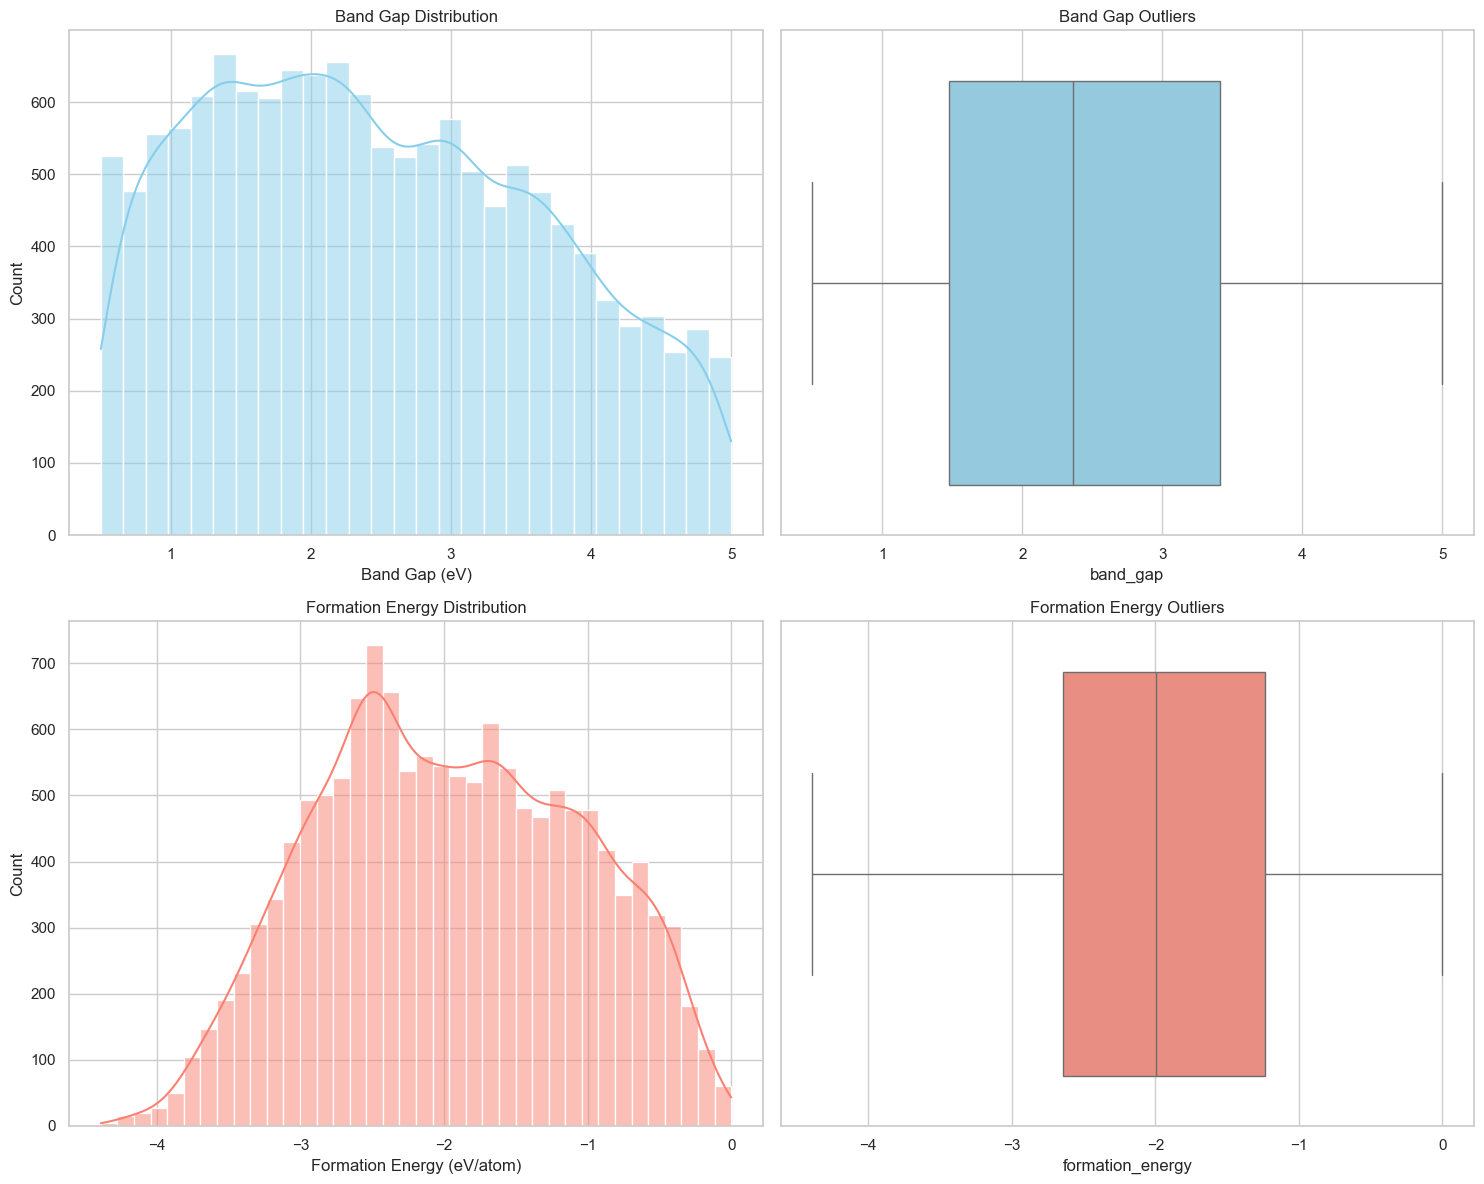

In [4]:
# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# --- Row 1: Band Gap ---
sns.histplot(df['band_gap'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Band Gap Distribution')
axes[0, 0].set_xlabel('Band Gap (eV)')

sns.boxplot(x=df['band_gap'], ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Band Gap Outliers')

# --- Row 2: Formation Energy ---
sns.histplot(df['formation_energy'], kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Formation Energy Distribution')
axes[1, 0].set_xlabel('Formation Energy (eV/atom)')

sns.boxplot(x=df['formation_energy'], ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('Formation Energy Outliers')

plt.tight_layout()
plt.show()

In [5]:
def get_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    return outliers, lower_limit, upper_limit

# Check Band Gap
bg_outliers, bg_low, bg_high = get_outliers(df, 'band_gap')
print(f"BG Outlier Range: Below {bg_low:.2f} or Above {bg_high:.2f}")
print(f"Total FE Outliers: {len(bg_outliers)} out of {len(df)}")

# Check Formation Energy
fe_outliers, fe_low, fe_high = get_outliers(df, 'formation_energy')
print(f"FE Outlier Range: Below {fe_low:.2f} or Above {fe_high:.2f}")
print(f"Total FE Outliers: {len(fe_outliers)} out of {len(df)}")

BG Outlier Range: Below -1.42 or Above 6.31
Total FE Outliers: 0 out of 13819
FE Outlier Range: Below -4.76 or Above 0.88
Total FE Outliers: 0 out of 13819


Targets are Clean